# Laboratorio de Imágenes: Segmentación Aórtica y Flujometría Cuantitativa en 2D PC-MRI
## De los Principios Físicos de Phase Contrast a la Segmentación Avanzada (Hough + Otsu + Watershed)

---

## 1. Explicación Intuitiva y Física de la Secuencia Phase Contrast (PC-MRI)

### ¿Cómo mide la Resonancia Magnética la velocidad de la sangre?

<p align="center">
  <img src="https://raw.githubusercontent.com/pamelaFranco/Laboratorio-Imagenes/main/imagenes/PC.png" width="65%">
</p>

Imagina los protones de hidrógeno presentes en las moléculas de agua de la sangre como **pequeños corredores llevando un reloj de aguja** (su momento magnético o *spin*).

1. **Precesión y Frecuencia de Larmor**: En presencia del campo magnético principal ($B_0$), las agujas de todos los protones giran a una velocidad fija denominada frecuencia de Larmor ($\omega_0 = \gamma B_0$).
2. **Gradientes de Campo Magnético**: Se aplica un campo magnético adicional que varía linealmente a lo largo del espacio. Esto hace que las agujas de los relojes giren más rápido en un extremo del paciente y más lento en el opuesto.
3. **Gradiente Bipolar (Par de Pulsos de Codificación)**:
   * **Primer pulso (+)**: Acelera el giro de las agujas hacia adelante durante un tiempo determinado.
   * **Segundo pulso (-)**: Aplica inmediatamente un gradiente de magnitud opuesta para hacer que las agujas retrocedan exactamente la misma cantidad.

#### Comportamiento del Tejido Estacionario vs. Sangre en Movimiento
* **Tejido Estacionario (Músculo, Grasa, Hueso)**: El protón permanece en la misma posición durante ambos pulsos. Recibe el empuje hacia adelante y el empuje hacia atrás en el mismo punto del espacio. La aguja vuelve exactamente a cero. **Cambio de fase neto = $0$**.
* **Sangre en Movimiento**: El protón se desplaza por la arteria mientras se aplican los pulsos. Cuando se aplica el segundo pulso, el protón ya se encuentra en una nueva posición espacial con un campo magnético distinto. La aguja no regresa a cero, acumulando un desfase angular o **fase neta ($\Delta \phi$)**.

---

## 2. Formulación Matemática y Calibración de Rango Dinámico (`vmin`, `vmax`)

La diferencia de fase $\Delta \phi(x,y)$ es directamente proporcional a la velocidad del flujo sanguíneo $v(x,y)$:

$$\Delta \phi(x, y) = \gamma \cdot v(x, y) \cdot \Delta M_1$$

### Sensibilidad de Velocidad ($\text{VENC}$) y Centrado de Escala
El parámetro $\text{VENC}$ define la escala máxima de velocidad que el resonador puede codificar sin que la fase exceda $\pm \pi$ radianes ($\pm 180^\circ$):

$$v(x, y) = \frac{\phi(x, y)}{\pi} \cdot \text{VENC}$$

<p align="center">
  <img src="https://raw.githubusercontent.com/pamelaFranco/Laboratorio-Imagenes/main/imagenes/VENC2.png" width="50%">
</p>

**Codificación de velocidad de fase y fenómeno de solapamiento (*aliasing*).** A las velocidades en dirección positiva se les asignan valores de desfase entre 0° y 180°, mientras que a las velocidades opuestas se les asignan entre 0° y -180°. Representándolo mediante la escala de colores *Parula*, los 0° se representan con el color verde-azulado, mientras que a los +180° y -180° se les asignan los colores amarillo y azul, respectivamente. Las velocidades en la aorta ascendente (AAo) se muestran de azul-verdoso a amarillo, mientras que las de la aorta descendente (DAo) se muestran de azul-verdoso a azul. **(a)** Con una VENC establecida en 150 cm/s, una velocidad de 112,5 cm/s da como resultado un cambio de fase de +135°. **(b)** Con una VENC reducida a 75 cm/s, en la AAo la velocidad del flujo excede la VENC especificada, produciendo *aliasing* (solapamiento de velocidad) y un salto falso a valores negativos (-135°). El mapa de colores original ha sido adaptado a *Parula* para una mejor visualización.


<p align="center">
  <img src="https://raw.githubusercontent.com/pamelaFranco/Laboratorio-Imagenes/main/imagenes/VENC1.png" width="60%">
</p>

Para visualizar el flujo con el contraste correcto, la escala de color se fija simétricamente alrededor de cero:

$$\text{Rango de Color} = [-\text{Velocidad}_{\max}, \, +\text{Velocidad}_{\max}] = [-155\text{ cm/s}, \, +155\text{ cm/s}]$$

* **Flujo Anterógrado ($v > 0$)**: Tonos cálidos (amarillos/rojos).
* **Flujo Nulo ($v = 0$)**: Tono neutro verde-azulado.
* **Flujo Retrógrado ($v < 0$)**: Tonos fríos (azules oscuros).

---

## 3. Estrategias de Segmentación: ¿Anatómica o Funcional?


<p align="center">
  <img src="https://raw.githubusercontent.com/pamelaFranco/Laboratorio-Imagenes/main/imagenes/PC2.png" width="60%">
</p>

**Imágenes de contraste de fase (PC) de la aorta ascendente (AAo) y descendente (DAo) de un voluntario.** **(a)** Imagen de diferencia de fase en el pico sistólico (*peak-systole*). **(b)** Imagen de magnitud; en ambas imágenes se demarcaron las regiones de interés (ROI, del inglés *region-of-interest*). **(c)** Imágenes de diferencia de fase a lo largo de las distintas fases del ciclo cardíaco. **(d)** Gráfico de flujo versus tiempo, donde el flujo en cada fase temporal se obtiene al multiplicar la velocidad promedio en cada ROI ($\text{cm/s}$) por el área correspondiente ($\text{cm}^2$), resultando en un flujo volumétrico ($\text{cm}^3/\text{s}$). El mapa de colores ha sido adaptado (de escala de grises a *Parula*) para una mejor visualización.

En el procesamiento de imágenes 2D PC-MRI existen dos paradigmas para delimitar la aorta:

1. **Segmentación Anatómica (`BW.mat`)**:
   * Delimita la pared del vaso a partir de la intensidad en la imagen de magnitud.
   * **Ventaja**: Mantiene el área transversal completa de la arteria, incluyendo los bordes del vaso donde la velocidad decae progresivamente por fricción viscosa.
2. **Segmentación Funcional / Hemodinámica (sobre la Imagen de Fase `Data150.mat`)**:
   * Aplica umbralización directa de Otsu sobre la magnitud de la velocidad $\vert{}u(x,y)\vert{}$.
   * **Ventaja**: Permite seleccionar dinámicamente el núcleo de flujo rápido y filtrar regiones con flujo estancado o ruido estático en tiempo real.

---
### 4. Naturaleza Compleja de la Señal en PC-MRI (Parte Real e Imaginaria)

En Resonancia Magnética con Contraste de Fase (PC-MRI), la señal adquirida en cada píxel $S(x,y)$ no es un número entero ni un escalar simple, sino un **número complejo** definido por su parte real e imaginaria:

$$S(x,y) = \text{Re}\{S(x,y)\} + i \cdot \text{Im}\{S(x,y)\}$$

A partir de las componentes real e imaginaria de la señal espectral, el resonador reconstruye dos tipos de imágenes con significados físicos completamente distintos:

* **Imagen de Magnitud ($|S|$ - Anatómica):**
  Calcula la amplitud o intensidad de la magnetización transversal mediante la norma vectorial:
  $$|S(x,y)| = \sqrt{\text{Re}\{S(x,y)\}^2 + \text{Im}\{S(x,y)\}^2}$$
  * **Significado físico:** Refleja la densidad de protones y las propiedades de relajación del tejido ($T_1$/$T_2$). Es una imagen puramente anatómica en escala de grises.

* **Imagen de Fase ($\phi$ - Hemodinámica/Velocidad):**
  Calcula el ángulo de desfase de los espines en el plano transversal usando la función arcotangente de dos argumentos:
  $$\phi(x,y) = \arctan2\Big(\text{Im}\{S(x,y)\}, \, \text{Re}\{S(x,y)\}\Big)$$
  * **Significado físico:** Mide el cambio de fase acumulado por el movimiento de los protones de la sangre a través del gradiente de campo magnético. Este ángulo $\phi$ es directamente proporcional a la velocidad del flujo $v(x,y)$.

> **Nota de implementación en Python:**
> En el código siguiente, la variable `s` representa la combinación compleja de las bobinas/pulsos ($s = s_1 \cdot s_2^*$). De ella extraemos la magnitud con `np.abs(s)` y la fase con `np.arctan2(np.imag(s), np.real(s))`.

---

## 5. Separación de Estructuras Circulares mediante Filtro Watershed (Paso a Paso)

Cuando la aorta ascendente y descendente entran en contacto en el plano axial, el algoritmo *Watershed* las desvincula utilizando la **Transformada de Distancia Euclidiana (EDT)**:

1. **Transformada de Distancia Euclidiana (EDT)**:
   Calcula la distancia de cada píxel interior al borde más cercano:
   $$D(p) = \min_{q \in \text{Fondo}} \Vert{} p - q \Vert{}_2$$
   Para secciones circulares, $D(p)$ forma una superficie cónica 3D cuyo punto más alto está en el centro exacto del vaso.
2. **Inversión Topográfica $-D(p)$**:
   Convierte los picos cónicos en cuencas o valles profundos de inundación.
3. **Marcadores Centrales**:
   Se extraen los picos locales de $D(p)$, generando un único marcador en el centro de cada vaso.
4. **Líneas Divisoras de Agua**:
   El agua asciende desde los marcadores centrales. Al encontrarse los frentes de inundación de ambas arterias, se erigen presas topográficas que las separan de forma limpia.

In [1]:
# Instalar dependencias e importar librerías necesarias
import os
import requests
import numpy as np
import scipy.io
import scipy.ndimage as ndi
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import cv2
from skimage import filters, segmentation, feature
import ipywidgets as widgets
from IPython.display import clear_output, display

# --- DEFINICIÓN DEL COLORMAP PERCEPTUAL PARULA ---
parula_data = [
    [0.2081, 0.1663, 0.5292], [0.2116, 0.1898, 0.5777], [0.2123, 0.2138, 0.6270],
    [0.2081, 0.2386, 0.6771], [0.1959, 0.2645, 0.7279], [0.1707, 0.2919, 0.7792],
    [0.1253, 0.3209, 0.8299], [0.0591, 0.3518, 0.8790], [0.0117, 0.3837, 0.8853],
    [0.0060, 0.4152, 0.8601], [0.0090, 0.4462, 0.8352], [0.0117, 0.4768, 0.8105],
    [0.0125, 0.5072, 0.7858], [0.0112, 0.5374, 0.7609], [0.0071, 0.5674, 0.7357],
    [0.0004, 0.5973, 0.7099], [0.0101, 0.6268, 0.6830], [0.0461, 0.6558, 0.6545],
    [0.0988, 0.6841, 0.6241], [0.1623, 0.7115, 0.5914], [0.2323, 0.7377, 0.5562],
    [0.3060, 0.7626, 0.5183], [0.3813, 0.7858, 0.4776], [0.4566, 0.8073, 0.4343],
    [0.5307, 0.8268, 0.3886], [0.6025, 0.8442, 0.3408], [0.6713, 0.8593, 0.2913],
    [0.7364, 0.8719, 0.2405], [0.7972, 0.8819, 0.1891], [0.8533, 0.8890, 0.1384],
    [0.9042, 0.8931, 0.0917], [0.9493, 0.8944, 0.0545], [0.9880, 0.8927, 0.0345],
    [0.9893, 0.9056, 0.1315], [0.9871, 0.9238, 0.2227], [0.9822, 0.9438, 0.3110],
    [0.9748, 0.9649, 0.3971], [0.9714, 0.9850, 0.4820]
]
parula_cmap = LinearSegmentedColormap.from_list("parula", parula_data)

print("Librerías y Colormap 'parula' cargados exitosamente.")

Librerías y Colormap 'parula' cargados exitosamente.


### 6. Carga de Datos, Reconstrucción de Fase (`cardiac_phase = 3`) y Recortes Anatómicos (`rect` y `rect2`)

Se descarga el dataset, se realiza la reconstrucción de fase continua en el **pico sistólico** (`cardiac_phase = 3`), y se extraen las regiones de interés:
* **`rect = [36.5100, 140.5100, 39.9800, 45.9800]`**: Aorta Ascendente y Descendente.
* **`rect2 = [3.5100, 7.5100, 14.9800, 15.9800]`**: Aorta Ascendente (AAo).

Magnitud anatómica extraída con éxito -> mag_crop_aortas: (46, 40)


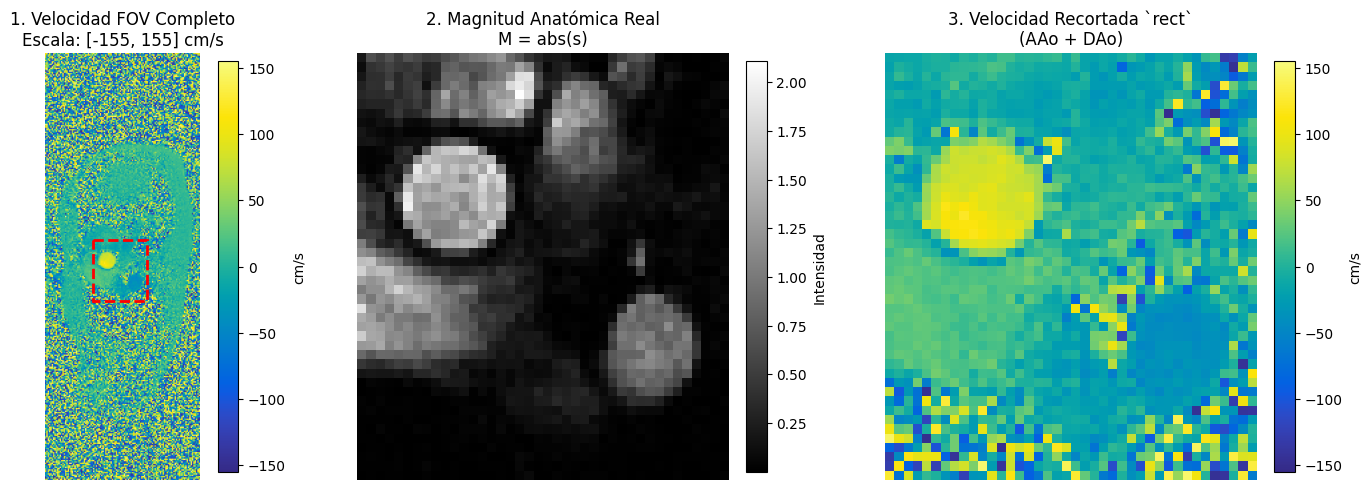

In [2]:
# Descarga de datos desde GitHub
url_data150 = "https://raw.githubusercontent.com/pamelaFranco/Laboratorio-Imagenes/main/imagenes/Data150.mat"

if not os.path.exists("Data150.mat"):
    r_d150 = requests.get(url_data150)
    with open("Data150.mat", "wb") as f:
        f.write(r_d150.content)

mat_d150 = scipy.io.loadmat("Data150.mat")
key_vel = [k for k in mat_d150.keys() if not k.startswith('__')][0]
raw_data = mat_d150[key_vel]

# --- RECONSTRUCCIÓN DE FASE Y MAGNITUD REAL (PICO SISTÓLICO) ---
cardiac_phase_idx = 2  # Fase 3 del ciclo cardíaco (0-based)
venc_val = 150.0       # VENC = 150 cm/s
value = 155.0          # Rango simétrico [-155, 155]

if np.iscomplexobj(raw_data) and raw_data.ndim >= 4:
    if raw_data.ndim == 5:
        data_p1 = raw_data[:, :, cardiac_phase_idx, 0, :]
        data_p2 = raw_data[:, :, cardiac_phase_idx, 1, :]
    elif raw_data.ndim == 4:
        data_p1 = raw_data[:, :, 0, :]
        data_p2 = raw_data[:, :, 1, :]

    # Señal Compleja Combinada s
    s = np.sum(data_p1 * np.conj(data_p2), axis=-1)

    # 1. Extracción de Fase -> Velocidad u(x,y)
    phase_slice = np.arctan2(np.imag(s), np.real(s))
    u_sistolico = phase_slice * (venc_val / np.pi)

    # 2. Extracción de Magnitud Anatómica Real M(x,y) = abs(s)
    mag_sistolico = np.abs(s)
else:
    phase_slice = raw_data[:, :, cardiac_phase_idx] if raw_data.ndim > 2 else raw_data
    u_sistolico = phase_slice * (venc_val / np.pi) if np.max(np.abs(phase_slice)) <= np.pi + 1e-3 else phase_slice
    mag_sistolico = np.abs(u_sistolico)

# --- FUNCIÓN DE RECORTE RECTANGULAR ---
def crop_region(img, rect_vec):
    xmin, ymin, w, h = rect_vec
    r_start = max(0, int(round(ymin)) - 1)
    r_end = min(img.shape[0], int(round(ymin + h)))
    c_start = max(0, int(round(xmin)) - 1)
    c_end = min(img.shape[1], int(round(xmin + w)))
    return img[r_start:r_end, c_start:c_end]

# Vectores rect y rect2
rect = [36.5100, 140.5100, 39.9800, 45.9800]  # AAo + DAo
rect2 = [3.5100, 7.5100, 14.9800, 15.9800]    # AAo

# Recortes de Velocidad y Magnitud Anatómica
u_crop_aortas = crop_region(u_sistolico, rect)
mag_crop_aortas = crop_region(mag_sistolico, rect)
u_crop_aao = crop_region(u_crop_aortas, rect2)

# Normalizar la magnitud recortada para binarización
bw_img = (mag_crop_aortas - mag_crop_aortas.min()) / (mag_crop_aortas.max() - mag_crop_aortas.min() + 1e-8)

print(f"Magnitud anatómica extraída con éxito -> mag_crop_aortas: {mag_crop_aortas.shape}")

# --- VISUALIZACIÓN DE VELOCIDAD Y MAGNITUD ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. FOV Completo de Velocidad
im0 = axes[0].imshow(u_sistolico, cmap=parula_cmap, vmin=-value, vmax=value)
axes[0].set_title(f"1. Velocidad FOV Completo\nEscala: [-{value:.0f}, {value:.0f}] cm/s")
axes[0].axis('off')
rect_box = plt.Rectangle((rect[0]-1, rect[1]-1), rect[2], rect[3], edgecolor='red', facecolor='none', linewidth=2, linestyle='--')
axes[0].add_patch(rect_box)
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label='cm/s')

# 2. Magnitud Anatómica Real M = abs(s) Recortada
im1 = axes[1].imshow(mag_crop_aortas, cmap='gray')
axes[1].set_title("2. Magnitud Anatómica Real\nM = abs(s)")
axes[1].axis('off')
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04, label='Intensidad')

# 3. Velocidad Recortada (AAo + DAo)
im2 = axes[2].imshow(u_crop_aortas, cmap=parula_cmap, vmin=-value, vmax=value)
axes[2].set_title("3. Velocidad Recortada `rect`\n(AAo + DAo)")
axes[2].axis('off')
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04, label='cm/s')

plt.tight_layout()
plt.show()

In [8]:
# ==============================================================================
# ANÁLISIS DE FLUJO MRI 4D FLOW
# Rango de eje de flujo fijado de -300 a 300 cm³/s para evitar cortes en DAo/AAo
# ==============================================================================

import os
import requests
import scipy.io
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import ipywidgets as widgets
from IPython.display import display

# ------------------------------------------------------------------------------
# 1. DESCARGA Y CARGA DEL DATASET
# ------------------------------------------------------------------------------
url_data150 = "https://raw.githubusercontent.com/pamelaFranco/Laboratorio-Imagenes/main/imagenes/Data150.mat"
filename = "Data150.mat"

if not os.path.exists(filename):
    r = requests.get(url_data150)
    with open(filename, "wb") as f:
        f.write(r.content)

mat_d150 = scipy.io.loadmat(filename)
key_vel = [k for k in mat_d150.keys() if not k.startswith('__')][0]
raw_data = mat_d150[key_vel]

# ------------------------------------------------------------------------------
# 2. PROCESAMIENTO DE TODAS LAS FASES CARDÍACAS
# ------------------------------------------------------------------------------
venc_val = 150.0  # VENC = 150 cm/s
rect = [36.5100, 140.5100, 39.9800, 45.9800]  # Recorte Aortas [xmin, ymin, w, h]

def crop_region(img, rect_vec):
    xmin, ymin, w, h = rect_vec
    r_start = max(0, int(round(ymin)) - 1)
    r_end = min(img.shape[0], int(round(ymin + h)))
    c_start = max(0, int(round(xmin)) - 1)
    c_end = min(img.shape[1], int(round(xmin + w)))
    return img[r_start:r_end, c_start:c_end]

n_phases = raw_data.shape[2] if raw_data.ndim >= 3 else 1

u_crop_list, mag_crop_list = [], []
for t_idx in range(n_phases):
    if np.iscomplexobj(raw_data) and raw_data.ndim >= 4:
        if raw_data.ndim == 5:
            data_p1, data_p2 = raw_data[:, :, t_idx, 0, :], raw_data[:, :, t_idx, 1, :]
        elif raw_data.ndim == 4:
            data_p1, data_p2 = raw_data[:, :, 0, :], raw_data[:, :, 1, :]
        s = np.sum(data_p1 * np.conj(data_p2), axis=-1)
        phase_slice = np.arctan2(np.imag(s), np.real(s))
        u_t = phase_slice * (venc_val / np.pi)
        mag_t = np.abs(s)
    else:
        phase_slice = raw_data[:, :, t_idx] if raw_data.ndim > 2 else raw_data
        u_t = phase_slice * (venc_val / np.pi) if np.max(np.abs(phase_slice)) <= np.pi + 1e-3 else phase_slice
        mag_t = np.abs(u_t)

    u_crop_list.append(crop_region(u_t, rect))
    mag_crop_list.append(crop_region(mag_t, rect))

u_crop_all = np.array(u_crop_list)     # Shape: (fases, alto, ancho)
mag_crop_all = np.array(mag_crop_list) # Shape: (fases, alto, ancho)

h_crop, w_crop = u_crop_all.shape[1], u_crop_all.shape[2]
time_vec = np.linspace(0.08, 0.9, n_phases)
pixel_area_cm2 = (1.5 / 10.0)**2  # Resolución espacial ~1.5 mm

def create_circular_mask(h, w, center, radius):
    Y, X = np.ogrid[:h, :w]
    return np.sqrt((X - center[0])**2 + (Y - center[1])**2) <= radius

# ------------------------------------------------------------------------------
# 3. RENDERIZADO DINÁMICO E INTERACTIVO
# ------------------------------------------------------------------------------
def render_interactive(phase_idx, aao_x, aao_y, aao_r, dao_x, dao_y, dao_r):
    # Máscaras circulares definidas por los alumnos
    mask_aao = create_circular_mask(h_crop, w_crop, (aao_x, aao_y), aao_r)
    mask_dao = create_circular_mask(h_crop, w_crop, (dao_x, dao_y), dao_r)

    # Cálculo dinámico de curvas de flujo Q(t)
    q_aao = np.array([np.sum(u_frame[mask_aao]) * pixel_area_cm2 for u_frame in u_crop_all])
    q_dao = np.array([np.sum(u_frame[mask_dao]) * pixel_area_cm2 for u_frame in u_crop_all])

    fig = plt.figure(figsize=(15, 8.5), dpi=100)
    gs = fig.add_gridspec(2, 3, height_ratios=[1.1, 1], width_ratios=[1, 1, 1.3])

    ax_a = fig.add_subplot(gs[0, 0])
    ax_b = fig.add_subplot(gs[0, 1])
    ax_d = fig.add_subplot(gs[0, 2])
    ax_c = fig.add_subplot(gs[1, :])

    # --- (a) Mapa de Velocidad de la Fase Seleccionada ---
    u_frame = u_crop_all[phase_idx]
    ax_a.imshow(u_frame, cmap='turbo', vmin=-180, vmax=180)
    ax_a.set_title(f"(a) Velocidad - Fase {phase_idx+1}/{n_phases}", fontsize=11, fontweight='bold')
    ax_a.axis('off')

    ax_a.add_patch(patches.Circle((aao_x, aao_y), aao_r, edgecolor='red', facecolor='none', linewidth=2))
    ax_a.text(aao_x, aao_y + aao_r + 3, "AAo", color='red', fontsize=11, fontweight='bold', ha='center')

    ax_a.add_patch(patches.Circle((dao_x, dao_y), dao_r, edgecolor='#337ab7', facecolor='none', linewidth=2))
    ax_a.text(dao_x, dao_y + dao_r + 3, "DAo", color='#337ab7', fontsize=11, fontweight='bold', ha='center')

    # --- (b) Magnitud Anatómica de la Fase Seleccionada ---
    mag_frame = mag_crop_all[phase_idx]
    ax_b.imshow(mag_frame, cmap='gray')
    ax_b.set_title(f"(b) Magnitud Anatómica - Fase {phase_idx+1}/{n_phases}", fontsize=11, fontweight='bold')
    ax_b.axis('off')

    ax_b.add_patch(patches.Circle((aao_x, aao_y), aao_r, edgecolor='red', facecolor='none', linewidth=2))
    ax_b.text(aao_x, aao_y + aao_r + 3, "AAo", color='red', fontsize=11, fontweight='bold', ha='center')

    ax_b.add_patch(patches.Circle((dao_x, dao_y), dao_r, edgecolor='#337ab7', facecolor='none', linewidth=2))
    ax_b.text(dao_x, dao_y + dao_r + 3, "DAo", color='#337ab7', fontsize=11, fontweight='bold', ha='center')

    # --- (d) Curva de Flujo Q(t) con rango de eje [-300, 300] cm³/s ---
    ax_d.plot(time_vec, q_aao, 's-', color='red', label='AAo', linewidth=2, markersize=6)
    ax_d.plot(time_vec, q_dao, '^-', color='#337ab7', label='DAo', linewidth=2, markersize=6)

    # Indicador de la fase actual seleccionada
    ax_d.axvline(time_vec[phase_idx], color='black', linestyle='--', linewidth=1.5, label=f'Fase actual ({phase_idx+1})')
    ax_d.axhline(0, color='gray', linewidth=0.8)

    ax_d.set_title("(d) Curva de Flujo Cardiovascular", fontsize=11, fontweight='bold')
    ax_d.set_xlabel("Tiempo (s)")
    ax_d.set_ylabel("Flujo (cm³/s)")

    # RANGO DE EJE CORREGIDO: [-300, 300] cm³/s
    ax_d.set_ylim(-300, 300)

    ax_d.grid(True, linestyle=':', alpha=0.6)
    ax_d.legend(loc='upper right', fontsize=9)

    # --- (c) Secuencia Temporal Completa ---
    cols = 10
    rows = int(np.ceil(n_phases / cols))
    gs_c = ax_c.get_subplotspec().subgridspec(rows, cols, wspace=0.05, hspace=0.05)
    ax_c.axis('off')
    ax_c.set_title("(c) Evolución Temporal Completa", fontsize=11, fontweight='bold', pad=8)

    for i in range(n_phases):
        r, c = divmod(i, cols)
        sub_ax = fig.add_subplot(gs_c[r, c])
        im_c = sub_ax.imshow(u_crop_all[i], cmap='turbo', vmin=-180, vmax=180)

        # Destacar la fase activa con borde rojo en la grilla
        if i == phase_idx:
            for spine in sub_ax.spines.values():
                spine.set_edgecolor('red')
                spine.set_linewidth(2.5)
            sub_ax.set_xticks([])
            sub_ax.set_yticks([])
        else:
            sub_ax.axis('off')

    cbar_ax = fig.add_axes([0.92, 0.12, 0.015, 0.3])
    cbar = fig.colorbar(im_c, cax=cbar_ax)
    cbar.set_label('(cm/s)', fontsize=9)

    plt.tight_layout(rect=[0, 0, 0.9, 1])
    plt.show()

# ------------------------------------------------------------------------------
# 4. CONTROLES Y SLIDERS (INTERFAZ DE USUARIO)
# ------------------------------------------------------------------------------
w_phase = widgets.IntSlider(value=3, min=0, max=n_phases-1, step=1, description='Fase (Frame):', layout=widgets.Layout(width='400px'))

# Sliders AAo (Aorta Ascendente)
w_aao_x = widgets.FloatSlider(value=13.5, min=2.0, max=w_crop-2, step=0.5, description='AAo X:')
w_aao_y = widgets.FloatSlider(value=13.5, min=2.0, max=h_crop-2, step=0.5, description='AAo Y:')
w_aao_r = widgets.FloatSlider(value=6.5, min=2.0, max=15.0, step=0.5, description='AAo Radio:')

# Sliders DAo (Aorta Descendente)
w_dao_x = widgets.FloatSlider(value=27.5, min=2.0, max=w_crop-2, step=0.5, description='DAo X:')
w_dao_y = widgets.FloatSlider(value=27.5, min=2.0, max=h_crop-2, step=0.5, description='DAo Y:')
w_dao_r = widgets.FloatSlider(value=5.5, min=2.0, max=15.0, step=0.5, description='DAo Radio:')

ui = widgets.VBox([
    widgets.HTML("<h3>Ajuste Interactivo de ROIs Aortas y Navegación de Fases</h3>"),
    widgets.HBox([w_phase]),
    widgets.HTML("<b>Aorta Ascendente (AAo - Rojo):</b>"),
    widgets.HBox([w_aao_x, w_aao_y, w_aao_r]),
    widgets.HTML("<b>Aorta Descendente (DAo - Azul):</b>"),
    widgets.HBox([w_dao_x, w_dao_y, w_dao_r])
])

out = widgets.interactive_output(render_interactive, {
    'phase_idx': w_phase,
    'aao_x': w_aao_x,
    'aao_y': w_aao_y,
    'aao_r': w_aao_r,
    'dao_x': w_dao_x,
    'dao_y': w_dao_y,
    'dao_r': w_dao_r
})

display(ui, out)

Output()

### 7. Localización de la Aorta Descendente por Transformada de Hough Circular (CHT)

La **Transformada de Hough Circular (CHT)** es una técnica de procesamiento digital de imágenes diseñada para detectar formas circulares, incluso cuando los contornos se encuentran ruidosos o incompletos. En el contexto de la resonancia magnética aórtica, permite identificar de manera robusta el centroide y el radio de la Aorta Descendente a partir de la máscara anatómica.

---

#### 1. Concepto Intuitivo: El Sistema de Votación

El algoritmo opera transformando los puntos del plano de la imagen a un **espacio de parámetros** (o espacio acumulador):

1. **Votación:** Cada píxel perteneciente al borde de una estructura "vota" por todas las posibles posiciones del centro $(a, b)$ de un círculo de radio $R$ que podría pasar por él.
2. **Matriz Acumuladora:** Se construye una matriz 3D con ejes $(a, b, R)$. Cada vez que un centro candidato es calculado a partir de un punto del borde, la celda correspondiente en la matriz suma $+1$.
3. **Detección del Centroide:** Los círculos trazados desde los píxeles del contorno aórtico se intersectarán en un mismo punto del espacio acumulador. La celda con la mayor cantidad de votos (pico de intensidad) determina las coordenadas del centro $(a, b)$ y el radio $R$ del vaso.

---

#### 2. Ecuaciones del Algoritmo

La ecuación cartesiana de una circunferencia de centro $(a, b)$ y radio $R$ en el plano de la imagen $(x, y)$ es:

$$(x - a)^2 + (y - b)^2 = R^2$$

Expresada en forma paramétrica en función del ángulo $\theta$:

$$x = a + R \cdot \cos(\theta)$$
$$y = b + R \cdot \sin(\theta)$$

Para determinar la ubicación del centro $(a, b)$ a partir de un punto de borde conocido $(x_i, y_i)$, se despeja el centroide en el espacio de parámetros para $\theta \in [0, 2\pi)$:

$$a = x_i - R \cdot \cos(\theta)$$
$$b = y_i - R \cdot \sin(\theta)$$

Cuando el radio $R$ es conocido o acotado en un rango $[R_{\min}, R_{\max}]$, cada píxel de borde $(x_i, y_i)$ genera un círculo de centros posibles en el espacio acumulador $(a, b)$.

---

#### 3. Flujo de Trabajo para la Segmentación Aórtica

1. **Detección de Bordes:** Se aplica un operador de gradiente (como Canny o Sobel) sobre la máscara de anatomía para aislar los píxeles del contorno.
2. **Definición del Rango de Radios:** Se delimita el intervalo de búsqueda $[R_{\min}, R_{\max}]$ en píxeles, ajustado a las dimensiones anatómicas de la aorta.
3. **Acumulación de Votos:** Se evalúa la ecuación paramétrica para cada píxel de borde y se incrementa el contador en el acumulador $A(a, b, R)$.
4. **Extracción de Parámetros:** Se busca el máximo global $\max(A(a, b, R))$, obteniendo las coordenadas exactas del centroide aórtico y el radio estimado.

In [3]:
def descending_aorta_crop(bw, min_r=1, max_r=10):
    """
    Normaliza la matriz binaria e identifica la Aorta Descendente por CHT.
    """
    gray_image = (bw - bw.min()) / (bw.max() - bw.min() + 1e-8)
    gray_8u = (gray_image * 255).astype(np.uint8)

    circles = cv2.HoughCircles(
        gray_8u,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=10,
        param1=50,
        param2=10,
        minRadius=min_r,
        maxRadius=max_r
    )

    if circles is not None:
        circles = circles[0, :]
        idx_max = np.argmax(circles[:, 2])
        x_cent, y_cent, radius = circles[idx_max]

        size_cropped = 3 * radius
        xmin = x_cent - size_cropped / 2.0
        ymin = y_cent - size_cropped / 2.0
        rect_out = [xmin, ymin, size_cropped, size_cropped]
        return rect_out, (x_cent, y_cent, radius)
    else:
        return None, None

### 8. Laboratorio Interactivo: Pipeline de Segmentación y Mapeo Hemodinámico en PC-MRI

Esta interfaz integra un pipeline dinámico de procesamiento digital de imágenes para la identificación y cuantificación de flujos vasculares a partir de datos de Resonancia Magnética de Contraste de Fase (PC-MRI).

---

#### 1. Selección de la Imagen Fuente ($I_{\text{src}}$)

El usuario puede alternar la superficie de procesamiento entre la información anatómica o la información funcional:

$$I_{\text{src}}(x,y) = \begin{cases} |s(x,y)| & \text{Modo Magnitud Anatómica Real} \\ |u(x,y)| & \text{Modo Velocidad Absoluta } [\text{cm/s}] \end{cases}$$

---

#### 2. Umbralización de Otsu Modificada por Escala ($k$)

Se calcula el umbral óptimo global $t^*$ que maximiza la varianza entre clases $\sigma_B^2(t)$ sobre los píxeles con señal positiva de $I_{\text{src}}$:

$$t^* = \arg\max_{t} \sigma_B^2(t) = \arg\max_{t} \left( \omega_0(t) \omega_1(t) \left[ \mu_0(t) - \mu_1(t) \right]^2 \right)$$

Para permitir la contracción o expansión dinámica del contorno, se aplica el **Factor Otsu** ($k$):

$$t_{\text{aplicado}} = k \cdot t^*$$

Generando la máscara binaria $B(x,y)$:

$$B(x,y) = \begin{cases} 1 & \text{si } I_{\text{src}}(x,y) \ge t_{\text{aplicado}} \\ 0 & \text{en otro caso} \end{cases}$$

---

#### 3. Transformada de Distancia Euclidiana (EDT)

Sobre la máscara binaria $B(x,y)$ se calcula el mapa de distancia $D(p)$, donde cada píxel $p = (x,y) \in B$ recibe un valor igual a la distancia euclidiana hacia el punto más cercano del fondo ($q \notin B$):

$$D(p) = \min_{q \notin B} \|p - q\|_2 = \min_{q \notin B} \sqrt{(x_p - x_q)^2 + (y_p - y_q)^2}$$

Las regiones centrales de las arterias alcanzan los máximos locales de $D(p)$.

---

#### 4. Detección de Semillas (Máximos Locales)

Se identifican las semillas para la separación de estructuras mediante la búsqueda de picos en el mapa de distancia, condicionados a una distancia mínima de separación $d_{\min}$ (`dist_semillas`):

$$S = \left\{ p \in B \;\middle|\; D(p) = \max_{q \in \mathcal{N}_{d_{\min}}(p)} D(q) \right\}$$

Donde $\mathcal{N}_{d_{\min}}(p)$ es la vecindad de radio $d_{\min}$ alrededor del píxel $p$. Las semillas detectadas se etiquetan para formar la matriz de marcadores iniciales $M_{\text{marcadores}}(x,y)$.

---

#### 5. Segmentación por Algoritmo Watershed (Cuenca Hidrográfica)

El algoritmo Watershed interpreta el inverso del mapa de distancia $-D(p)$ como un relieve topográfico. La inundación comienza desde los marcadores $M_{\text{marcadores}}$ restringida al dominio de la máscara $B(x,y)$:

$$L(x,y) = \text{Watershed}\Big(-D(x,y), \; M_{\text{marcadores}}(x,y), \; B(x,y)\Big)$$

El resultado $L(x,y)$ asigna una etiqueta entera única $\{1, 2, \dots, N\}$ a cada vaso sanguíneo detectado individualmente.

---

#### 6. Mapeo Sincronizado de Velocidad Aórtica

Finalmente, la máscara segmentada de vasos $L(x,y)$ se multiplica puntualmente por el mapa de velocidad $u(x,y)$ para aislar exclusivamente la dinámica del flujo vascular respetando la escala visual $[-V_{\max}, V_{\max}]$ (`max_val_scale`):

$$v_{\text{aorta}}(x,y) = \begin{cases} u(x,y) & \text{si } L(x,y) > 0 \\ 0 & \text{en otro caso} \end{cases}$$

In [4]:
def laboratorio_interactivo_pc_mri(
    modo_segmentacion='Magnitud Anatómica Real (abs(s))',
    factor_otsu=1.0,
    dist_semillas=5,
    radio_min_hough=1,
    radio_max_hough=10,
    max_val_scale=155.0
):
    """
    Pipeline interactivo que permite segmentar sobre la Magnitud Anatómica Real abs(s)
    o sobre el Mapa de Velocidad Absoluta |u(x,y)|.
    """
    clear_output(wait=True)
    plt.close('all')

    if 'mag_crop_aortas' not in globals() or 'u_crop_aortas' not in globals():
        print("Por favor ejecuta primero la CELDA DE CÓDIGO 2.")
        return

    # 1. Localización CHT sobre la magnitud
    rect_hough, circle_info = descending_aorta_crop(bw_img, radio_min_hough, radio_max_hough)

    # 2. Selección de la imagen fuente para Otsu
    if modo_segmentacion == 'Magnitud Anatómica Real (abs(s))':
        src_image = mag_crop_aortas
        label_histograma = "Intensidad de Magnitud M = abs(s)"
    else:
        src_image = np.abs(u_crop_aortas)
        label_histograma = "Velocidad Absoluta |u| [cm/s]"

    # 3. Umbralización de Otsu
    t_base = filters.threshold_otsu(src_image[src_image > 0])
    t_aplicado = t_base * factor_otsu
    mask_binaria = src_image >= t_aplicado

    # 4. Transformada de Distancia Euclidiana (EDT)
    dist_map = ndi.distance_transform_edt(mask_binaria)

    # 5. Detección de Semillas / Marcadores
    picos = feature.peak_local_max(dist_map, min_distance=dist_semillas, labels=mask_binaria)
    mask_picos = np.zeros(dist_map.shape, dtype=bool)
    if len(picos) > 0:
        mask_picos[tuple(picos.T)] = True
    marcadores, num_vasos = ndi.label(mask_picos)

    # 6. Algoritmo Watershed
    labels_watershed = segmentation.watershed(-dist_map, marcadores, mask=mask_binaria)

    # 7. Mapeo de Velocidad Sincronizado
    vel_aorta = np.where(labels_watershed > 0, u_crop_aortas, 0)

    # --- DESPLIEGUE GRÁFICO DINÁMICO ---
    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(2, 3)

    # Panel 1: Histograma y Umbral
    ax_hist = fig.add_subplot(gs[0, 0])
    ax_hist.hist(src_image.ravel(), bins=30, color='gray', alpha=0.7, density=True)
    ax_hist.axvline(t_base, color='green', linestyle='--', linewidth=2, label=f'Otsu base = {t_base:.1f}')
    ax_hist.axvline(t_aplicado, color='red', linestyle='-', linewidth=2, label=f'Umbral = {t_aplicado:.1f}')
    ax_hist.set_title(f"1. Histograma ({modo_segmentacion.split()[0]})")
    ax_hist.set_xlabel(label_histograma)
    ax_hist.legend(loc='upper right', fontsize=8)

    # Panel 2: Binarización Resultante
    ax_bin = fig.add_subplot(gs[0, 1])
    ax_bin.imshow(mask_binaria, cmap='binary')
    ax_bin.set_title(f"2. Binarización (t = {t_aplicado:.1f})")
    ax_bin.axis('off')

    # Panel 3: CHT Hough en Aorta Descendente
    ax_cht = fig.add_subplot(gs[0, 2])
    ax_cht.imshow(mag_crop_aortas, cmap='gray')
    ax_cht.set_title("3. Localización DAo (Hough)")
    if circle_info is not None:
        xc, yc, r = circle_info
        ax_cht.add_patch(plt.Circle((xc, yc), r, color='red', fill=False, linewidth=2, label=f'DAo (r={r:.1f})'))
        if rect_hough is not None:
            xmin, ymin, sz, _ = rect_hough
            ax_cht.add_patch(plt.Rectangle((xmin, ymin), sz, sz, edgecolor='yellow', facecolor='none', linewidth=1.5, linestyle='--'))
        ax_cht.legend(loc='lower right', fontsize=8)
    ax_cht.axis('off')

    # Panel 4: Mapa de Distancia y Marcadores
    ax_dist = fig.add_subplot(gs[1, 0])
    ax_dist.imshow(dist_map, cmap='magma')
    if len(picos) > 0:
        ax_dist.plot(picos[:, 1], picos[:, 0], 'r*', markersize=9, label=f'Semillas ({len(picos)})')
        ax_dist.legend(loc='lower right', fontsize=8)
    ax_dist.set_title("4. Distancia D(p) + Marcadores")
    ax_dist.axis('off')

    # Panel 5: Watershed Final
    ax_ws = fig.add_subplot(gs[1, 1])
    ax_ws.imshow(labels_watershed, cmap='nipy_spectral')
    ax_ws.set_title(f"5. Watershed ({num_vasos} Vasos Detectados)")
    ax_ws.axis('off')

    # Panel 6: Mapa de Velocidad Aórtica Segmentado (Parula)
    ax_vel = fig.add_subplot(gs[1, 2])
    im_v = ax_vel.imshow(vel_aorta, cmap=parula_cmap, vmin=-max_val_scale, vmax=max_val_scale)
    ax_vel.set_title(f"6. Velocidad Aórtica (Parula)\nEscala: [-{max_val_scale:.0f}, {max_val_scale:.0f}] cm/s")
    ax_vel.axis('off')
    fig.colorbar(im_v, ax=ax_vel, fraction=0.046, pad=0.04, label='cm/s')

    plt.tight_layout()
    plt.show()

# Controles interactivos
widgets.interact(
    laboratorio_interactivo_pc_mri,
    modo_segmentacion=widgets.Dropdown(
        options=['Magnitud Anatómica Real (abs(s))', 'Imagen de Fase / Velocidad (|u|)'],
        value='Magnitud Anatómica Real (abs(s))',
        description='Modo:'
    ),
    factor_otsu=widgets.FloatSlider(min=0.2, max=1.8, step=0.05, value=1.0, description='Factor Otsu:'),
    dist_semillas=widgets.IntSlider(min=1, max=15, step=1, value=5, description='Dist. Semillas:'),
    radio_min_hough=widgets.IntSlider(min=1, max=10, step=1, value=1, description='Hough Min R:'),
    radio_max_hough=widgets.IntSlider(min=5, max=25, step=1, value=10, description='Hough Max R:'),
    max_val_scale=widgets.FloatSlider(min=50.0, max=250.0, step=5.0, value=155.0, description='Escala Max:')
);

interactive(children=(Dropdown(description='Modo:', options=('Magnitud Anatómica Real (abs(s))', 'Imagen de Fa…

---

## 9. Guía de Interpretación del Laboratorio Interactivo

### A. Comparativa de Modos de Segmentación

* **Magnitud Anatómica Real (`abs(s)`)**:
  * **Principio**: Opera sobre la intensidad de señal escalar $M(x,y) = \vert{}S(x, y)\vert{}$, extraída directamente de la interacción interferométrica del complejo conjugado multicanal.
  * **Comportamiento Hemodinámico**: Preserva la anatomía completa de la pared vascular. Es fundamental para delimitar el área de sección transversal real ($A$), ya que en la frontera con la pared arterial la velocidad del fluido decae hacia cero debido a la condición de no deslizamiento hidráulico.
  * **Respuesta al Deslizador**: Ajustar el **Factor Otsu** modula la sensibilidad frente al contraste de señal del tejido estacionario adyacente.

* **Imagen de Fase / Velocidad (`|u|`)**:
  * **Principio**: Umbraliza directamente el mapa continuo de magnitud de velocidad en unidades físicas ($\vert{}u(x,y)\vert{}$ en $\text{cm/s}$).
  * **Comportamiento Hemodinámico**: Aísla de forma exclusiva el núcleo de flujo hemodinámicamente activo (jet sistólico), filtrando áreas de flujo estancado, vórtices de baja velocidad o ruido de fondo.
  * **Respuesta al Deslizador**: Modificar el **Factor Otsu** equivale a cambiar el umbral de corte fisiológico de velocidad en $\text{cm/s}$.

---

### B. Análisis del Pipeline Algorítmico (Paneles 1 al 6)

1. **Panel 1 - Histograma y Umbralización**: Muestra la distribución estadística de intensidades o velocidades del bloque aórtico. La línea punteada verde señala el óptimo de Otsu $t^*$, mientras que la línea roja continua indica el umbral ajustado dinámicamente ($t = t^* \cdot \text{Factor}$).
2. **Panel 2 - Binarización**: Genera la máscara lógica $I(x,y) \ge t$. Si las aortas ascendente y descendente están muy próximas, aparecen interconectadas en un único componente conexo.
3. **Panel 3 - Detección por Hough (CHT)**: Aplica la Transformada de Hough Circular para aislar de forma automática la Aorta Descendente (DAo) identificando su centroide $(x_c, y_c)$ y radio $r$.
4. **Panel 4 - Mapa de Distancia (EDT) y Marcadores**: La Transformada de Distancia Euclidiana calcula $D(p) = \min \Vert{}p - q\Vert{}_2$ desde el interior del vaso hacia el fondo. Cada cono de distancia genera un máximo local marcando el centro geométrico de cada lumen (puntos rojos).
5. **Panel 5 - Segmentación Watershed**: Al invertir el mapa a $-D(p)$, las semillas actúan como orígenes de inundación. Cuando los frentes de agua colisionan en la zona de contacto entre vasos, se erigen crestas divisoras que separan mecánicamente la AAo de la DAo.
6. **Panel 6 - Mapa Flujométrico Segmentado**: Proyecta la máscara resultante sobre el mapa de velocidad de fase en la paleta perceptual `parula`. La escala simétrica $[-\text{Escala}_{\max}, +\text{Escala}_{\max}]$ fija el cero ($0\text{ cm/s}$) en el verde neutro, resaltando el perfil laminar de la eyección sistólica en tonos amarillos/cálidos.

---

### C. Guía Práctica de Ajuste de Deslizadores

* **Factor Otsu**: Controla la rigurosidad del filtro espacial. Un valor $< 1.0$ expande la máscara incorporando bordes de baja velocidad; un valor $> 1.0$ contrae la máscara hacia el centro del vaso.
* **Distancia Semillas**: Define la separación mínima en píxeles entre máximos locales en la EDT. Si se fijan valores muy bajos, el ruido puede generar sobre-segmentación; si es muy alto, no se detectarán ambos vasos.
* **Hough Min/Max R**: Delimita el rango de radios anatómicos en píxeles para la identificación de la Aorta Descendente mediante CHT.
* **Escala Max**: Ajusta el rango dinámico de color en la barra lateral. Permite saturar zonas de alta velocidad o inspeccionar detalles de flujos secundarios lentos.

---

## 10. Segmentación Avanzada Basada en Atlas y Análisis Multimodal

Además de las técnicas de umbralización e inundación (*Watershed*), en neuroimagen y física médica avanzada se utiliza la **segmentación basada en atlas**. Este método permite delimitar automáticamente múltiples estructuras corticales y subcorticales complejas mediante la deformación no rígida de un volumen patrón estandarizado (en espacio **MNI152** o **ICBM152**) hacia el espacio nativo de cada paciente.

<p align="center">
  <img src="https://raw.githubusercontent.com/pamelaFranco/Laboratorio-Imagenes/main/imagenes/brain3d.gif" width="70%" alt="Segmentación 3D Subcortical y Atlas Cerebral">
</p>

### Aplicación en Investigación y Referencia Bibliográfica

Es importante destacar que el atlas utilizado no es único; se selecciona en función de la patología y de la estructura anatómica de interés. Por ejemplo, en nuestro trabajo sobre psicosis de primer episodio se utilizó el atlas **PD25**, enfocado en áreas de sustancia gris profunda (núcleos subcorticales como el caudado, putamen, globo pálido, sustancia negra, tálamo y amígdala), las cuales son fundamentales para estudiar las vías dopaminérgicas:

> **Franco, P.**, Montalba, C., Caulier-Cisterna, R., Milovic, C., González, A., Ramirez-Mahaluf, J. P., Undurraga, J., Salas, R., Crossley, N., Tejos, C., & Uribe, S. (2025). *Interpretable machine learning model for characterizing magnetic susceptibility-based biomarkers in first episode psychosis*. **Computer Methods and Programs in Biomedicine**, 272, 109067. [https://doi.org/10.1016/j.cmpb.2025.109067](https://doi.org/10.1016/j.cmpb.2025.109067)

---

### Pipeline Típico de Segmentación Basada en Atlas

1. **Adquisición Multimodal**: Obtención de secuencias anatómicas de alta resolución (T1w) junto con secuencias funcionales o cuantitativas (ej. *Multi-echo GRE* para QSM/R2*, DTI para difusividad).
2. **Co-registro Intra-sujeto**: Alineamiento espacial rígido de las imágenes cuantitativas hacia la anatomía T1w del propio paciente.
3. **Normalización y Deformación No Rígida**: Transformación del mapa anatómico del sujeto hacia un espacio estereotáctico estándar (como MNI152) mediante campos de deformación no lineales.
4. **Propagación de Etiquetas del Atlas**: Transferencia de los contornos anatómicos pre-segmentados hacia las imágenes del paciente. El atlas seleccionado dependerá de la patología o estructura de interés (por ejemplo, atlas de sustancia gris profunda como **PD25** para trastornos motores o psiquiátricos, o parcelaciones corticales como **Desikan-Killiany** o **Harvard-Oxford** para demencias y patologías de la corteza).
5. **Cuantificación de Biomarcadores**: Extracción automatizada de parámetros físicos (susceptibilidad magnética en ppm, velocidad en cm/s, difusividad en $\text{mm}^2/\text{s}$ o métricas radiómicas) para análisis estadístico o modelos de *Machine Learning*.

---

### Software y Toolboxes Especializadas en Neuroimagen

Para realizar este procesamiento automatizado se emplean diversas herramientas bioinformáticas y suites de neuroimagen de estándar internacional:

1. **SPM12 (Statistical Parametric Mapping)**: Utilizado para co-registro, segmentación tisular y normalización espacial a espacio MNI.
2. **FreeSurfer / FSL**: Suites fundamentales para parcelación cortical, segmentación subcortical (*FIRST*) y análisis morfométrico basado en superficies.
3. **DSI Studio**: Software especializado en la reconstrucción de Tensores de Difusión (DTI), tractografía cuantitativa de fibra blanca y mapeo de conectividad.
4. **FANSI Toolbox / ROMEO**: Paquetes de procesamiento para *Quantitative Susceptibility Mapping* (QSM), *phase unwrapping* e inversión de dipolo magnético.
5. **ANTs (Advanced Normalization Tools)**: Algoritmos de alineamiento y deformación simétrica de alta precisión (*SyN*).